# 建筑业 · 逐表数据可视化分析

基于国家统计局「数据库 — 季度数据」对**建筑业**主题的 10 张数据表逐一进行可视化分析。

| # | 数据表（文件名） | 实际内容 | 时间范围 |
| --- | --- | --- | --- |
| 1 | 建筑业总产值 | 总产值及构成、竣工产值 | 2022Q2—2026Q3（累计） |
| 2 | 建筑业企业个数和用工情况 | 企业单位数、从业人数 | 2022Q2—2026Q3（累计） |
| 3 | 建筑业企业总收入 | **竣工房屋价值分类**（文件名错位） | 2022Q2—2026Q2（累计，缺 2026Q1） |
| 4 | 建筑业企业房屋建筑施工面积 | 施工面积、新开工面积 | 2022Q2—2026Q3（累计） |
| 5 | 建筑业企业房屋建筑竣工价值 | **企业总收入**（文件名错位） | 2017Q1 快照 |
| 6 | 建筑业企业房屋建筑竣工面积 | 竣工面积及八分类 | 2022Q2—2026Q3（累计） |
| 7 | 建筑业企业签订合同情况 | 合同总额、新签、结转 | 2022Q2—2026Q3（累计） |
| 8 | 建筑业企业利润 | 营业利润、利润总额、产值利润率 | 2017Q1 快照 |
| 9 | 建筑业企业费用情况 | 与表 8 内容重复（作一致性对比） | 2017Q1 快照 |
| 10 | 建筑业企业资产负债情况 | 资产、负债、流动资产等 | 2017Q1 快照 |

**口径与注意事项**：时序表均为**累计值**口径；企业财务指标（表 5/8/9/10）统计制度无四季度数据，
最近一期为 2017Q1 快照，仅作结构参考；下载文件中表 3 与表 5 的文件名与内容互换了，
本 Notebook 按文件名读取并在各单元格标注实际内容；"厂房竣工价值"仅 1 期有值，未纳入绘图。

In [1]:
# 0 环境与工具函数
import re
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = ['Times New Roman', 'SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.22
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['axes.titlesize'] = 12.5
plt.rcParams['axes.titleweight'] = 'bold'

QMAP = {'一': 1, '二': 2, '三': 3, '四': 4}
DATA_DIR = next(c for c in [Path('data'), Path('建筑业/data'), Path('.')]
                if (c / '建筑业总产值.csv').exists())
PAL = ['#0071e3', '#34c759', '#ff9f0a', '#ff375f', '#bf5af2', '#64d2ff', '#ffd60a', '#8e8e93', '#a2845e']


def load_table(fname):
    """解析国家统计局季度 CSV，返回 (季度列表[时间正序], {指标名: 数值列表})。缺报按季度轴对齐补 None。"""
    text = (DATA_DIR / fname).read_text(encoding='utf-8-sig')
    quarters, rows = None, {}
    for line in text.splitlines():
        if '\t' not in line:
            continue
        cells = [c.replace(',', '').strip() for c in line.split('\t')]
        first = re.sub(r'\s+', '', cells[0] or '')
        if first == '指标':
            quarters = []
            for c in cells[1:]:
                if not c:
                    continue
                m = re.match(r'(\d{4})年第([一二三四])季度', c)
                if m:
                    quarters.append(f'{m.group(1)}Q{QMAP[m.group(2)]}')
            continue
        if not first or first.startswith(('注', '数据库', '时间', '数据来源')):
            continue
        vals = []
        for c in cells[1:]:
            try:
                vals.append(float(c))
            except ValueError:
                vals.append(None)
        vals = (vals + [None] * len(quarters))[:len(quarters)]  # 按季度轴对齐
        rows[first] = vals
    quarters = list(reversed(quarters))
    rows = {k: list(reversed(v)) for k, v in rows.items()}
    return quarters, rows


def col(rows, prefix):
    key = next((k for k in rows if k.startswith(prefix)), None)
    if key is None:
        raise KeyError(f'未找到指标：{prefix}')
    return rows[key]


def nanify(vals):
    return np.array([np.nan if v is None else v for v in vals], dtype=float)


def short_q(q):
    return q[2:]


print('数据目录：', DATA_DIR.resolve())
print('工具函数加载完成，可逐格运行下方分析。')

数据目录： C:\Users\21409\Desktop\商业数据分析+数据可视化\数据可视化\国家统计局数据可视化分析\建筑业\data
工具函数加载完成，可逐格运行下方分析。


## 表 1 · 建筑业总产值（累计）

**图 1** 堆积柱状图：总产值构成（建筑工程 / 安装工程 / 装饰装修 / 其他）；
**图 2** 双轴折线：总产值与竣工产值（累计），右轴为**竣工产值率**（竣工产值 ÷ 总产值）。

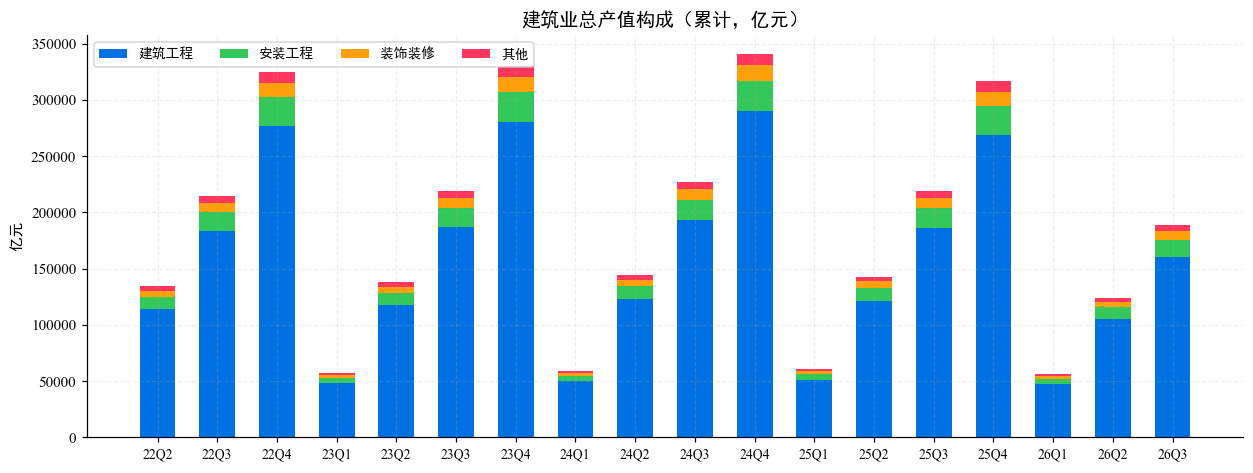

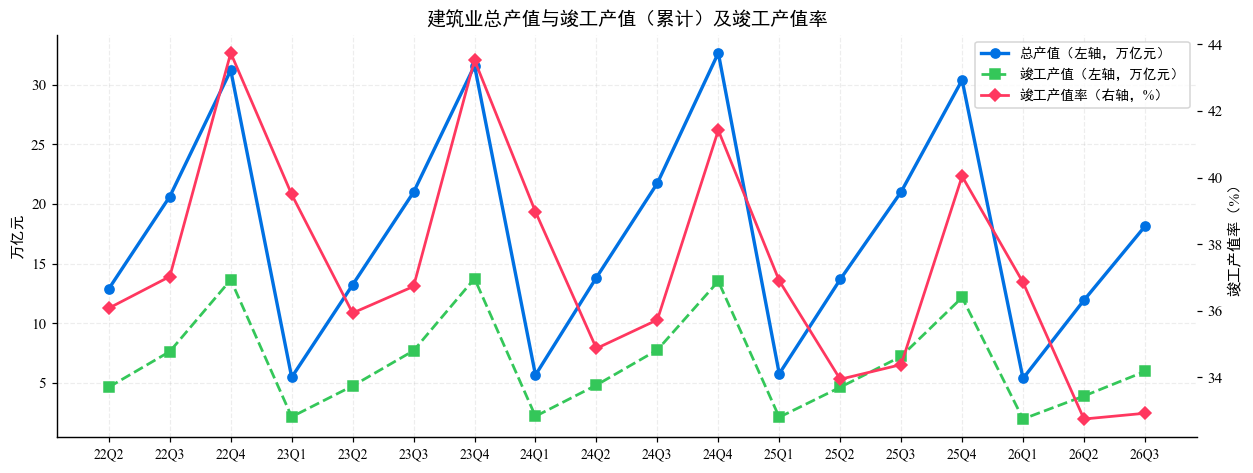

In [2]:
# 表 1：建筑业总产值
quarters, rows = load_table('建筑业总产值.csv')
x = np.arange(len(quarters))
labels = [short_q(q) for q in quarters]

gv = col(rows, '建筑业总产值累计值')
build = col(rows, '建筑工程产值累计值')
install = col(rows, '安装工程产值累计值')
decor = col(rows, '装饰装修产值累计值')
other = col(rows, '其他产值累计值')
gv_done = col(rows, '建筑业竣工产值累计值')

# 图 1：总产值构成堆积柱状图
fig, ax = plt.subplots(figsize=(11.5, 4.4))
bottom = np.zeros(len(quarters))
for i, (c, vals) in enumerate(zip(['建筑工程', '安装工程', '装饰装修', '其他'],
                                  [build, install, decor, other])):
    ax.bar(x, vals, 0.6, bottom=bottom, label=c, color=PAL[i])
    bottom += np.array(vals)
ax.set_xticks(x, labels, fontsize=9)
ax.set_ylabel('亿元')
ax.set_title('建筑业总产值构成（累计，亿元）')
ax.legend(ncol=4, loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

# 图 2：总产值 vs 竣工产值折线 + 竣工产值率（右轴）
done_rate = [d / g * 100 for d, g in zip(gv_done, gv)]
fig, ax = plt.subplots(figsize=(11.5, 4.4))
ax.plot(x, [v / 10000 for v in gv], 'o-', color=PAL[0], lw=2.2, label='总产值（左轴，万亿元）')
ax.plot(x, [v / 10000 for v in gv_done], 's--', color=PAL[1], lw=1.8, label='竣工产值（左轴，万亿元）')
ax2 = ax.twinx()
ax2.plot(x, done_rate, 'D-', color=PAL[3], lw=1.8, label='竣工产值率（右轴，%）')
ax2.set_ylabel('竣工产值率（%）')
ax2.grid(False)
ax.set_xticks(x, labels, fontsize=9)
ax.set_ylabel('万亿元')
ax.set_title('建筑业总产值与竣工产值（累计）及竣工产值率')
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper right', fontsize=9)
plt.tight_layout()
plt.show()

## 表 2 · 建筑业企业个数和用工情况（累计）

**图 1** 双轴组合图：企业单位数（柱）与从业人员（线，右轴）；
**图 2** 折线图：户均从业人数（从业人员 ÷ 企业数，反映平均企业规模）。

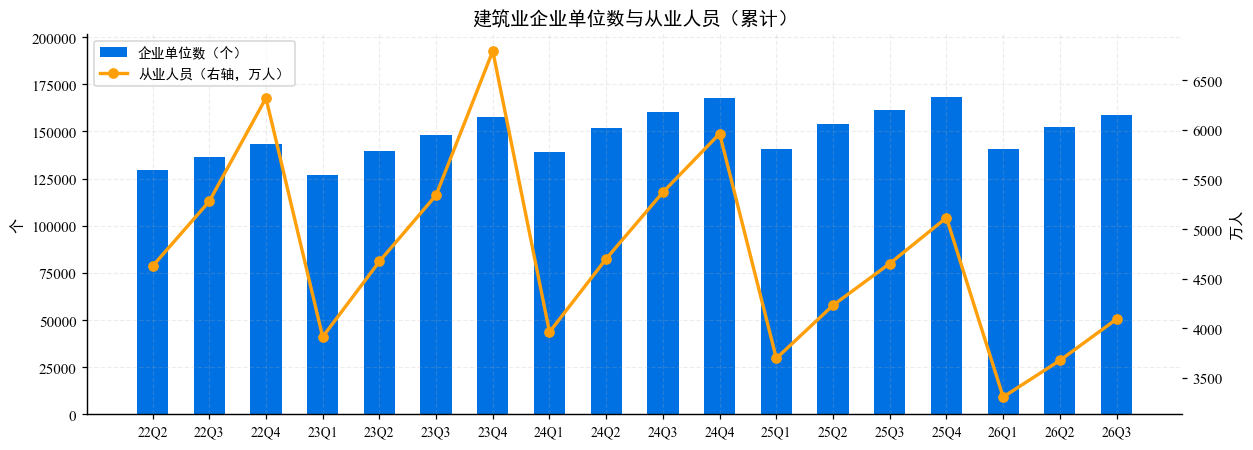

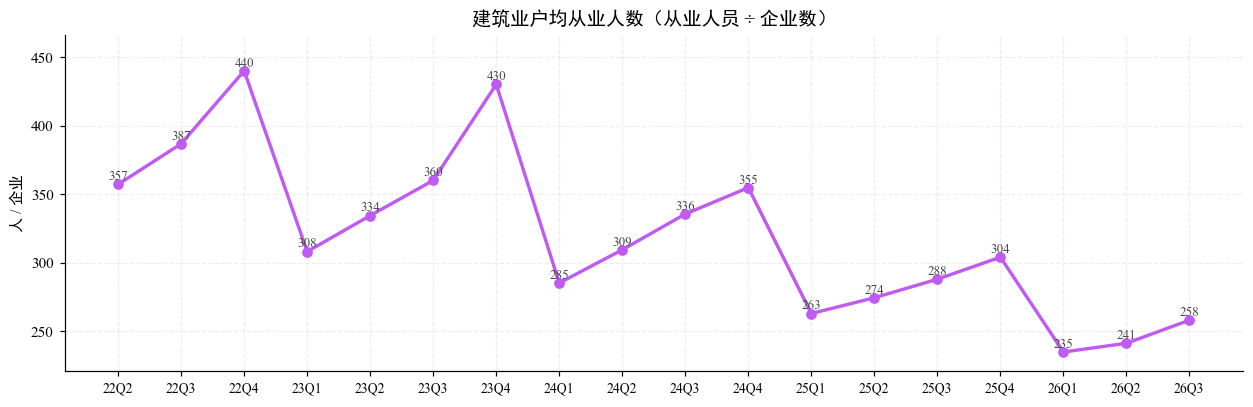

In [3]:
# 表 2：建筑业企业个数和用工情况
quarters, rows = load_table('建筑业企业个数和用工情况.csv')
x = np.arange(len(quarters))
labels = [short_q(q) for q in quarters]

firms = col(rows, '建筑业企业单位数累计值')
workers = col(rows, '直接从事生产经营活动的平均人数累计值')

# 图 1：双轴组合图
fig, ax = plt.subplots(figsize=(11.5, 4.2))
ax.bar(x, firms, 0.55, label='企业单位数（个）', color=PAL[0])
ax2 = ax.twinx()
ax2.plot(x, workers, 'o-', color=PAL[2], lw=2.2, label='从业人员（右轴，万人）')
ax2.set_ylabel('万人')
ax2.grid(False)
ax.set_xticks(x, labels, fontsize=9)
ax.set_ylabel('个')
ax.set_ylim(0, max(firms) * 1.2)
ax.set_title('建筑业企业单位数与从业人员（累计）')
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

# 图 2：户均从业人数折线
per_firm = [w * 10000 / f for w, f in zip(workers, firms)]
fig, ax = plt.subplots(figsize=(11.5, 3.8))
ax.plot(x, per_firm, 'o-', color=PAL[4], lw=2.2)
for xi, yi in zip(x, per_firm):
    ax.text(xi, yi + 3, f'{yi:.0f}', ha='center', fontsize=8.5, color='#444444')
ax.set_xticks(x, labels, fontsize=9)
ax.set_ylabel('人 / 企业')
ax.set_ylim(min(per_firm) * 0.94, max(per_firm) * 1.06)
ax.set_title('建筑业户均从业人数（从业人员 ÷ 企业数）')
plt.tight_layout()
plt.show()

## 表 3 · 建筑业企业总收入（实际内容：**竣工房屋价值分类**，累计）

> ⚠️ 该文件名与内容错位：文件名为"企业总收入"，内容为**竣工房屋价值分类**数据（2022Q2—2026Q2，缺 2026Q1）。

**图 1** 横向条形图：最新季度各类房屋竣工价值排行；
**图 2** 折线图：住宅房屋竣工价值占比（住宅 ÷ 竣工房屋价值合计）。

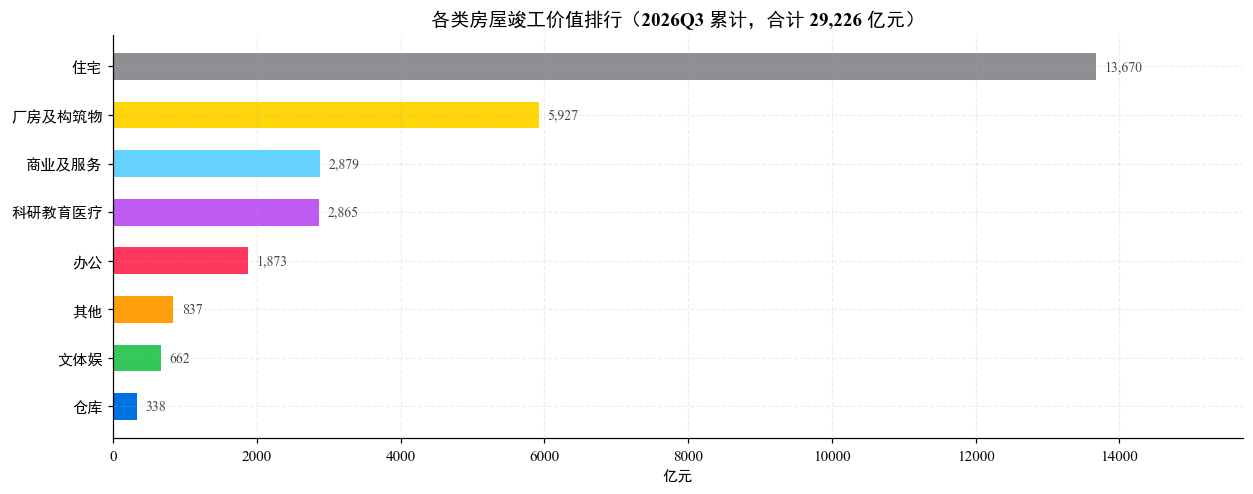

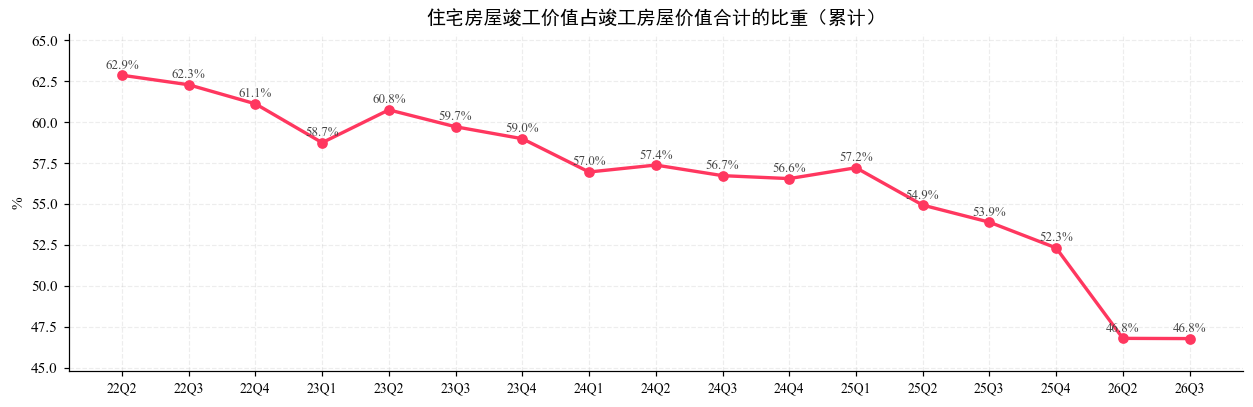

In [4]:
# 表 3：竣工房屋价值分类（文件名：建筑业企业总收入.csv）
quarters, rows = load_table('建筑业企业总收入.csv')
x = np.arange(len(quarters))
labels = [short_q(q) for q in quarters]

total_v = col(rows, '建筑业竣工房屋价值累计值')
CATS_V = [('住宅', '住宅房屋竣工价值累计值'), ('商业及服务', '商业及服务用房屋竣工价值累计值'),
          ('办公', '办公用房屋竣工价值累计值'), ('科研教育医疗', '科研、教育和医疗用房屋竣工价值累计值'),
          ('文体娱', '文化、体育和娱乐用房屋竣工价值累计值'), ('厂房及构筑物', '厂房及建筑物竣工价值累计值'),
          ('仓库', '仓库竣工价值累计值'), ('其他', '其他未列明的房屋建筑物竣工价值累计值')]

# 图 1：最新季度各类房屋竣工价值横向条形图
latest = len(quarters) - 1
pairs = sorted([(c, col(rows, p)[latest]) for c, p in CATS_V], key=lambda t: t[1])
fig, ax = plt.subplots(figsize=(11.5, 4.6))
bars = ax.barh([p[0] for p in pairs], [p[1] for p in pairs], 0.55,
               color=[PAL[i % len(PAL)] for i in range(len(pairs))])
for b, (_, v) in zip(bars, pairs):
    ax.text(v + total_v[latest] * 0.004, b.get_y() + b.get_height() / 2,
            f'{v:,.0f}', va='center', fontsize=9, color='#444444')
ax.set_xlim(0, max(p[1] for p in pairs) * 1.15)
ax.set_xlabel('亿元')
ax.set_title(f'各类房屋竣工价值排行（{quarters[latest]} 累计，合计 {total_v[latest]:,.0f} 亿元）')
plt.tight_layout()
plt.show()

# 图 2：住宅房屋竣工价值占比折线
res = col(rows, '住宅房屋竣工价值累计值')
share = [r / t * 100 for r, t in zip(res, total_v)]
fig, ax = plt.subplots(figsize=(11.5, 3.8))
ax.plot(x, share, 'o-', color=PAL[3], lw=2.2)
for xi, yi in zip(x, share):
    ax.text(xi, yi + 0.4, f'{yi:.1f}%', ha='center', fontsize=8.5, color='#444444')
ax.set_xticks(x, labels, fontsize=9)
ax.set_ylabel('%')
ax.set_ylim(min(share) - 2, max(share) + 2.5)
ax.set_title('住宅房屋竣工价值占竣工房屋价值合计的比重（累计）')
plt.tight_layout()
plt.show()

## 表 4 · 建筑业企业房屋建筑施工面积（累计）

**图 1** 双轴组合图：施工面积（柱）与新开工面积（线，右轴）；
**图 2** 面积图：新开工面积占施工面积比重。

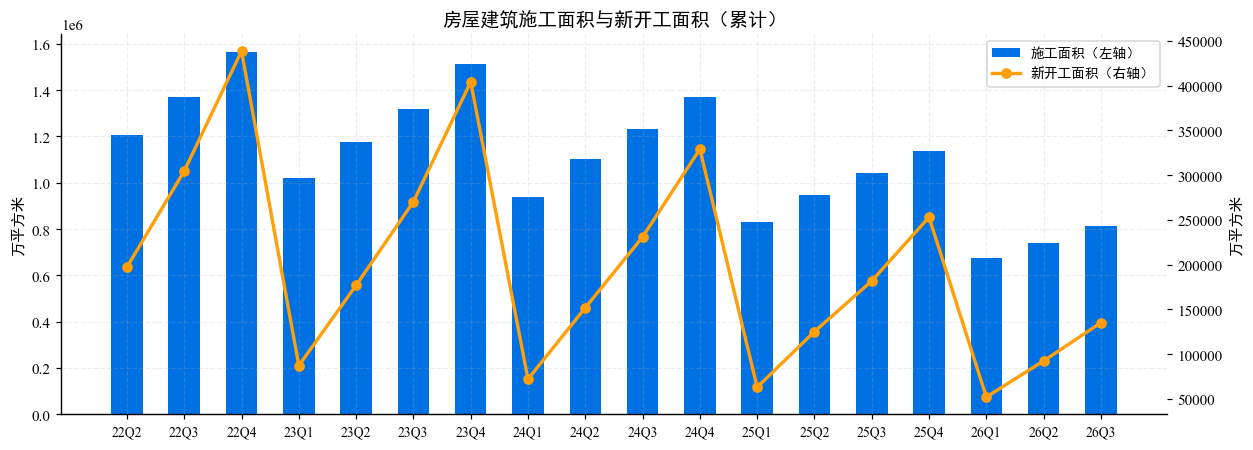

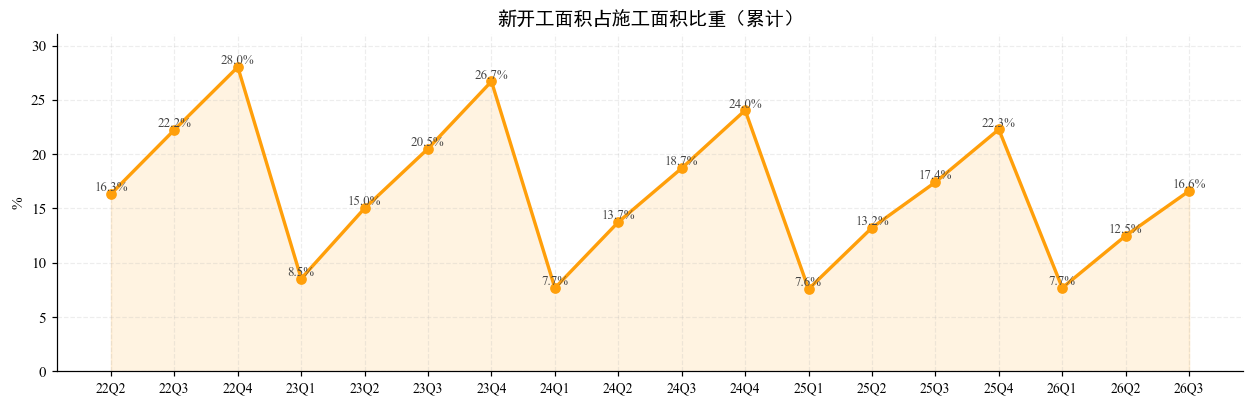

In [5]:
# 表 4：房屋建筑施工面积
quarters, rows = load_table('建筑业企业房屋建筑施工面积.csv')
x = np.arange(len(quarters))
labels = [short_q(q) for q in quarters]

under = col(rows, '房屋建筑施工面积累计值')
new = col(rows, '新开工面积累计值')

# 图 1：双轴组合图
fig, ax = plt.subplots(figsize=(11.5, 4.2))
ax.bar(x, under, 0.55, label='施工面积（左轴）', color=PAL[0])
ax2 = ax.twinx()
ax2.plot(x, new, 'o-', color=PAL[2], lw=2.2, label='新开工面积（右轴）')
ax2.set_ylabel('万平方米')
ax2.grid(False)
ax.set_xticks(x, labels, fontsize=9)
ax.set_ylabel('万平方米')
ax.set_title('房屋建筑施工面积与新开工面积（累计）')
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper right', fontsize=9)
plt.tight_layout()
plt.show()

# 图 2：新开工面积占比（面积图）
share = [n / u * 100 for n, u in zip(new, under)]
fig, ax = plt.subplots(figsize=(11.5, 3.8))
ax.plot(x, share, 'o-', color=PAL[2], lw=2.2)
ax.fill_between(x, 0, share, color=PAL[2], alpha=0.12)
for xi, yi in zip(x, share):
    ax.text(xi, yi + 0.25, f'{yi:.1f}%', ha='center', fontsize=8.5, color='#444444')
ax.set_xticks(x, labels, fontsize=9)
ax.set_ylabel('%')
ax.set_ylim(0, max(share) + 3)
ax.set_title('新开工面积占施工面积比重（累计）')
plt.tight_layout()
plt.show()

## 表 5 · 建筑业企业房屋建筑竣工价值（实际内容：**企业总收入**，2017Q1 快照）

**图 1** 横向条形图：总收入构成与主营成本，中心标注**主营业务成本率**。

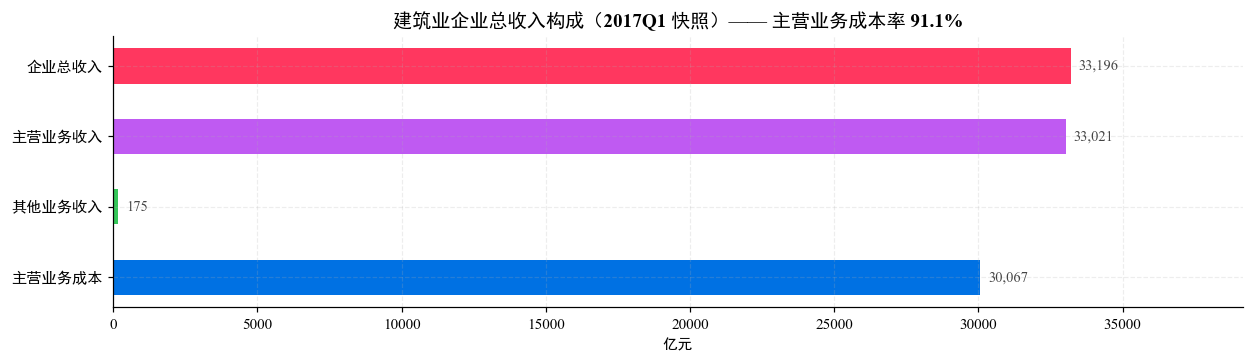

In [6]:
# 表 5：企业总收入快照（文件名：建筑业企业房屋建筑竣工价值.csv，2017Q1）
quarters, rows = load_table('建筑业企业房屋建筑竣工价值.csv')
rev_total = col(rows, '企业总收入累计值')[0]
rev_main = col(rows, '建筑业企业主营业务收入累计值')[0]
rev_other = col(rows, '建筑业企业其他业务收入累计值')[0]
cost_main = col(rows, '建筑业企业主营业务成本累计值')[0]

fig, ax = plt.subplots(figsize=(11.5, 3.4))
items = [('企业总收入', rev_total), ('主营业务收入', rev_main),
         ('其他业务收入', rev_other), ('主营业务成本', cost_main)]
bars = ax.barh([i[0] for i in items][::-1], [i[1] for i in items][::-1], 0.5,
               color=[PAL[0], PAL[1], PAL[4], PAL[3]])
for b, (_, v) in zip(bars, items[::-1]):
    ax.text(v + rev_total * 0.008, b.get_y() + b.get_height() / 2,
            f'{v:,.0f}', va='center', fontsize=9.5, color='#444444')
ax.set_xlim(0, rev_total * 1.18)
ax.set_xlabel('亿元')
cost_rate = cost_main / rev_main * 100
ax.set_title(f'建筑业企业总收入构成（{quarters[0]} 快照）—— 主营业务成本率 {cost_rate:.1f}%')
plt.tight_layout()
plt.show()

## 表 6 · 建筑业企业房屋建筑竣工面积（累计）

**图 1** 横向条形图：最新季度八分类竣工面积排行；
**图 2** 折线图：住宅竣工面积占竣工面积合计的比重。

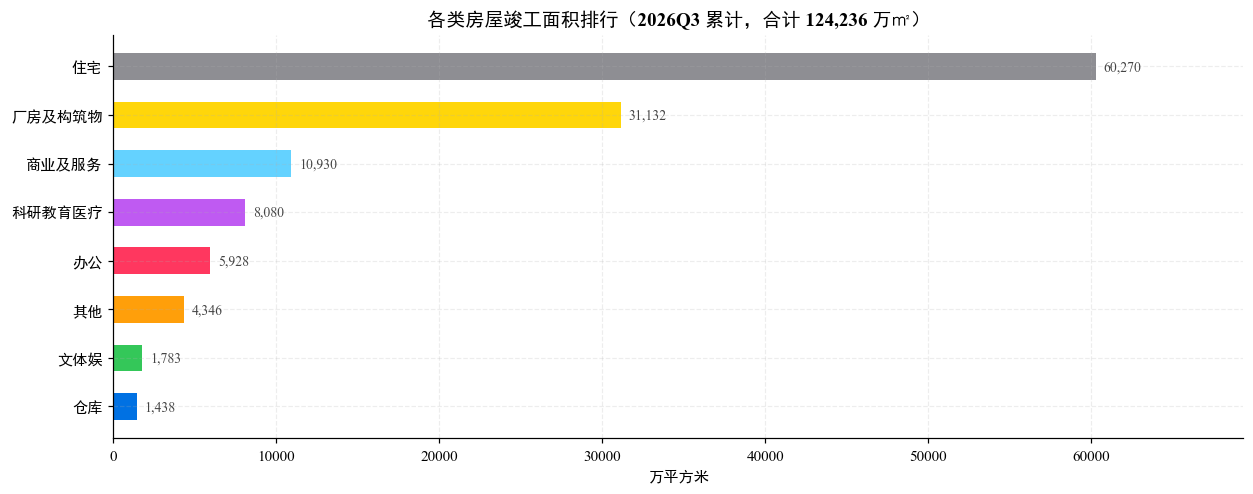

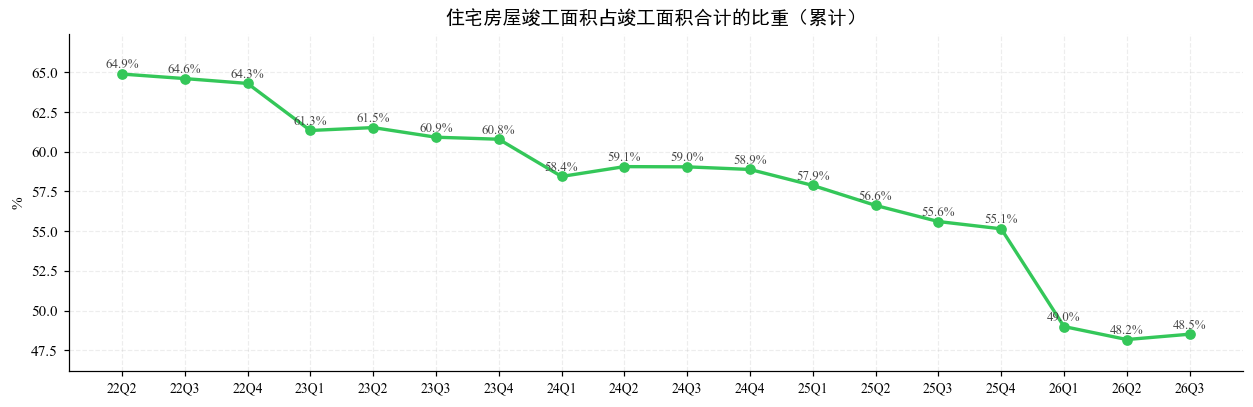

In [7]:
# 表 6：房屋建筑竣工面积分类
quarters, rows = load_table('建筑业企业房屋建筑竣工面积.csv')
x = np.arange(len(quarters))
labels = [short_q(q) for q in quarters]

area_done = col(rows, '房屋建筑竣工面积累计值')
CATS_A = [('住宅', '住宅房屋竣工面积累计值'), ('商业及服务', '商业及服务用房屋竣工面积累计值'),
          ('办公', '办公用房屋竣工面积累计值'), ('科研教育医疗', '科研、教育和医疗用房屋竣工面积累计值'),
          ('文体娱', '文化、体育和娱乐用房屋竣工面积累计值'), ('厂房及构筑物', '厂房及建筑物竣工面积累计值'),
          ('仓库', '仓库竣工面积累计值'), ('其他', '其他未列明的房屋建筑物竣工面积累计值')]

# 图 1：最新季度八分类竣工面积横向条形图
latest = len(quarters) - 1
pairs = sorted([(c, col(rows, p)[latest]) for c, p in CATS_A], key=lambda t: t[1])
fig, ax = plt.subplots(figsize=(11.5, 4.6))
bars = ax.barh([p[0] for p in pairs], [p[1] for p in pairs], 0.55,
               color=[PAL[i % len(PAL)] for i in range(len(pairs))])
for b, (_, v) in zip(bars, pairs):
    ax.text(v + area_done[latest] * 0.004, b.get_y() + b.get_height() / 2,
            f'{v:,.0f}', va='center', fontsize=9, color='#444444')
ax.set_xlim(0, max(p[1] for p in pairs) * 1.15)
ax.set_xlabel('万平方米')
ax.set_title(f'各类房屋竣工面积排行（{quarters[latest]} 累计，合计 {area_done[latest]:,.0f} 万㎡）')
plt.tight_layout()
plt.show()

# 图 2：住宅竣工面积占比折线
res = col(rows, '住宅房屋竣工面积累计值')
share = [r / t * 100 for r, t in zip(res, area_done)]
fig, ax = plt.subplots(figsize=(11.5, 3.8))
ax.plot(x, share, 'o-', color=PAL[1], lw=2.2)
for xi, yi in zip(x, share):
    ax.text(xi, yi + 0.35, f'{yi:.1f}%', ha='center', fontsize=8.5, color='#444444')
ax.set_xticks(x, labels, fontsize=9)
ax.set_ylabel('%')
ax.set_ylim(min(share) - 2, max(share) + 2.5)
ax.set_title('住宅房屋竣工面积占竣工面积合计的比重（累计）')
plt.tight_layout()
plt.show()

## 表 7 · 建筑业企业签订合同情况（累计）

**图 1** 堆积柱状图：本年新签 + 上年结转（构成合同总额），折线为合同总额（右轴）；
**图 2** 折线图：本年新签合同额占合同总额比重。

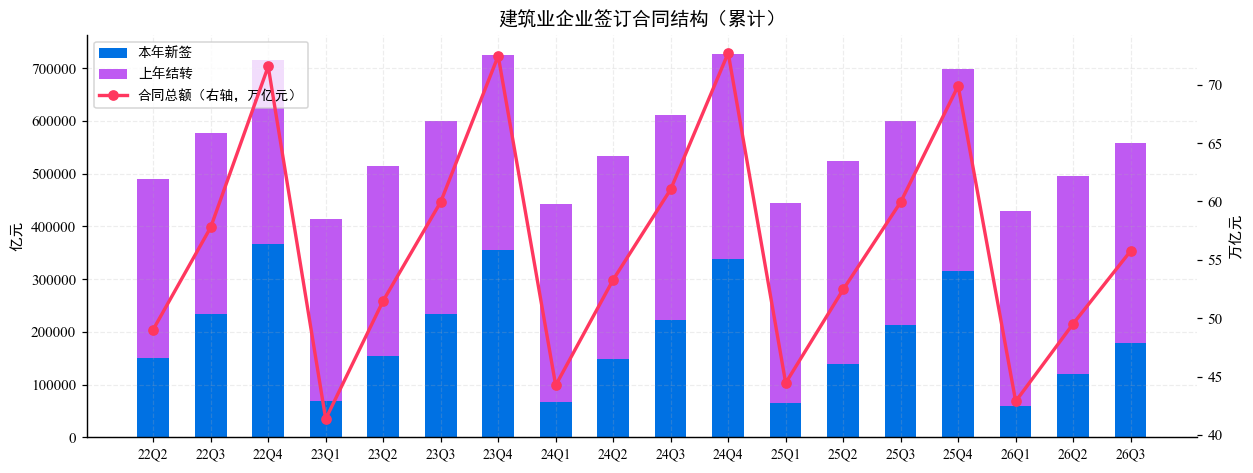

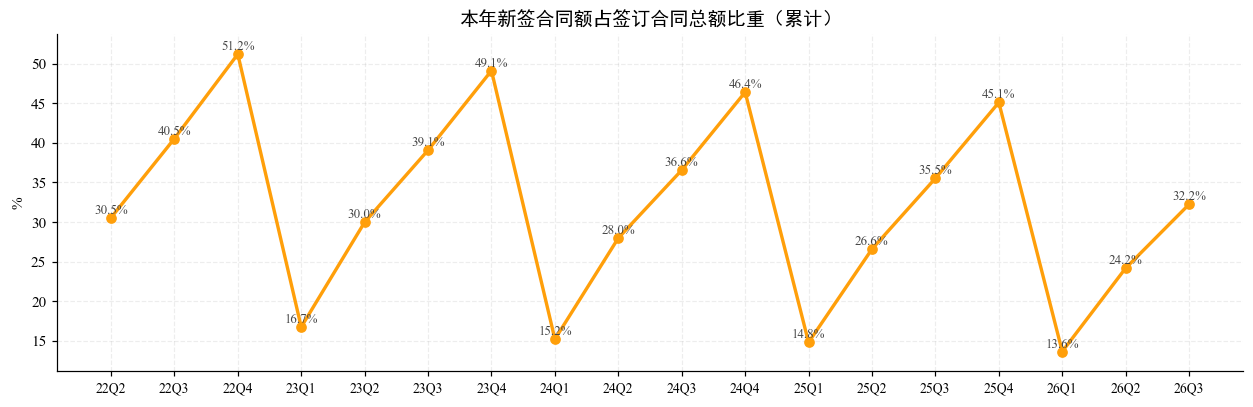

In [8]:
# 表 7：建筑业企业签订合同情况
quarters, rows = load_table('建筑业企业签订合同情况.csv')
x = np.arange(len(quarters))
labels = [short_q(q) for q in quarters]

contract = col(rows, '建筑业企业签订合同金额累计值')
contract_new = col(rows, '建筑业企业本年新签合同额累计值')
contract_carry = col(rows, '建筑业企业上年结转合同额累计值')

# 图 1：堆积柱 + 总额线（右轴）
fig, ax = plt.subplots(figsize=(11.5, 4.4))
ax.bar(x, contract_new, 0.55, label='本年新签', color=PAL[0])
ax.bar(x, contract_carry, 0.55, bottom=contract_new, label='上年结转', color=PAL[4])
ax2 = ax.twinx()
ax2.plot(x, [v / 10000 for v in contract], 'o-', color=PAL[3], lw=2.2, label='合同总额（右轴，万亿元）')
ax2.set_ylabel('万亿元')
ax2.grid(False)
ax.set_xticks(x, labels, fontsize=9)
ax.set_ylabel('亿元')
ax.set_title('建筑业企业签订合同结构（累计）')
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

# 图 2：本年新签占比折线
share = [n / t * 100 for n, t in zip(contract_new, contract)]
fig, ax = plt.subplots(figsize=(11.5, 3.8))
ax.plot(x, share, 'o-', color=PAL[2], lw=2.2)
for xi, yi in zip(x, share):
    ax.text(xi, yi + 0.5, f'{yi:.1f}%', ha='center', fontsize=8.5, color='#444444')
ax.set_xticks(x, labels, fontsize=9)
ax.set_ylabel('%')
ax.set_ylim(min(share) - 2.5, max(share) + 2.5)
ax.set_title('本年新签合同额占签订合同总额比重（累计）')
plt.tight_layout()
plt.show()

## 表 8 · 建筑业企业利润（2017Q1 快照）

**图 1** 柱状图：营业利润与利润总额对比（财务指标无四季度数据，最近一期为 2017Q1）。

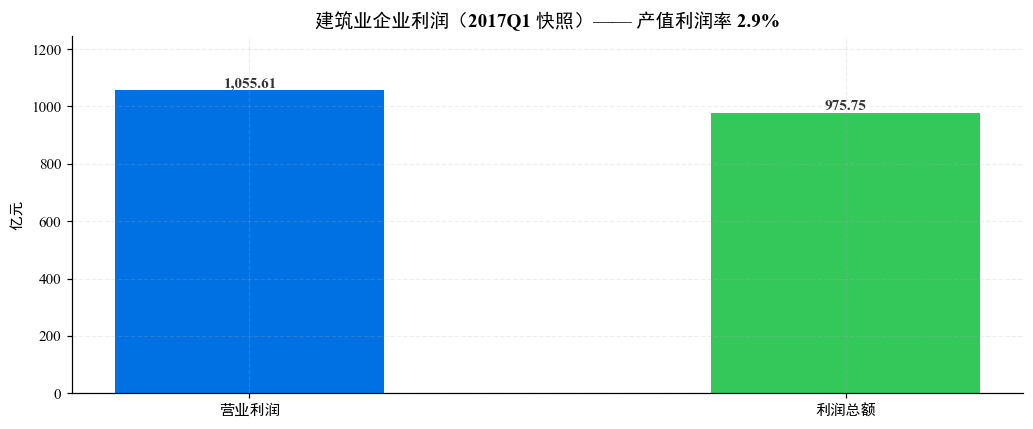

In [9]:
# 表 8：建筑业企业利润（2017Q1 快照）
quarters, rows = load_table('建筑业企业利润.csv')
oper = col(rows, '建筑业企业营业利润累计值')[0]
total = col(rows, '建筑业企业利润总额累计值')[0]
margin = col(rows, '建筑业企业产值利润率累计值')[0]

fig, ax = plt.subplots(figsize=(9.5, 4.0))
bars = ax.bar(['营业利润', '利润总额'], [oper, total], 0.45, color=[PAL[0], PAL[1]])
for b in bars:
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 12,
            f'{b.get_height():,.2f}', ha='center', fontsize=10, fontweight='bold', color='#333333')
ax.set_ylabel('亿元')
ax.set_ylim(0, max(oper, total) * 1.18)
ax.set_title(f'建筑业企业利润（{quarters[0]} 快照）—— 产值利润率 {margin}%')
plt.tight_layout()
plt.show()

## 表 9 · 建筑业企业费用情况（与表 8 内容重复）

> 注：该表与"建筑业企业利润.csv"内容完全相同（2017Q1 快照）。

**图 1** 并排柱状图：两张表同名指标逐项对比，验证数据一致性。

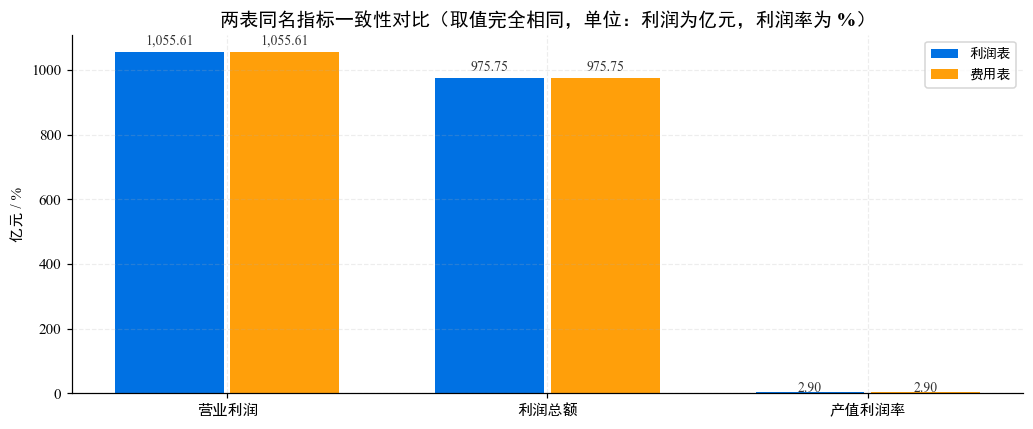

In [10]:
# 表 9：费用情况与利润表一致性对比
q1, r1_ = load_table('建筑业企业利润.csv')
q2, r2_ = load_table('建筑业企业费用情况.csv')
names = ['建筑业企业营业利润累计值', '建筑业企业利润总额累计值', '建筑业企业产值利润率累计值']
v1 = [col(r1_, n)[0] for n in names]
v2 = [col(r2_, n)[0] for n in names]
labels = ['营业利润', '利润总额', '产值利润率']

x = np.arange(len(names))
fig, ax = plt.subplots(figsize=(9.5, 4.0))
bars1 = ax.bar(x - 0.18, v1, 0.34, label='利润表', color=PAL[0])
bars2 = ax.bar(x + 0.18, v2, 0.34, label='费用表', color=PAL[2])
for b in list(bars1) + list(bars2):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() * 1.02,
            f'{b.get_height():,.2f}', ha='center', fontsize=9, color='#333333')
ax.set_xticks(x, labels)
ax.set_ylabel('亿元 / %')
ax.set_title('两表同名指标一致性对比（取值完全相同，单位：利润为亿元，利润率为 %）')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

## 表 10 · 建筑业企业资产负债情况（2017Q1 快照）

**图 1** 横向条形图：资产、负债与主要资产科目，标注**资产负债率**。

In [ ]:
# 表 10：建筑业企业资产负债情况（2017Q1 快照）
quarters, rows = load_table('建筑业企业资产负债情况.csv')
assets = col(rows, '建筑业企业资产累计值')[0]
liab = col(rows, '建筑业企业负债累计值')[0]
liquid = col(rows, '建筑业企业流动资产累计值')[0]
receivable = col(rows, '建筑业企业应收工程款累计值')[0]
inventory = col(rows, '建筑业企业存货累计值')[0]

items = [('资产总计', assets), ('负债合计', liab), ('流动资产', liquid),
         ('应收工程款', receivable), ('存货', inventory)]
pairs = sorted(items, key=lambda t: t[1])
fig, ax = plt.subplots(figsize=(11.5, 3.8))
bars = ax.barh([p[0] for p in pairs], [p[1] for p in pairs], 0.5,
               color=[PAL[i % len(PAL)] for i in range(len(pairs))])
for b, (_, v) in zip(bars, pairs):
    ax.text(v + assets * 0.008, b.get_y() + b.get_height() / 2,
            f'{v:,.0f}', va='center', fontsize=9.5, color='#444444')
ax.set_xlim(0, assets * 1.15)
ax.set_xlabel('亿元')
ratio = liab / assets * 100
ax.set_title(f'建筑业企业资产负债结构（{quarters[0]} 快照）—— 资产负债率 {ratio:.1f}%')
plt.tight_layout()
plt.show()